# RQ1新模型09：物理基线残差 + Extra Trees

这份Notebook不让机器学习从零预测整条轨迹，而是先由物理基线给出基础轨迹，再让Extra Trees预测其修正量：

[
\widehat{Y}=Y_{\mathrm{baseline}}+\widehat{R},
\qquad R=Y-Y_{\mathrm{baseline}}.
]

分别比较两种基础轨迹：

1. Velocity persistence；
2. Spatial mean flow。

这样可以检验：机器学习是否能够专门学习物理基线没有解释的部分。为了避免交叉验证泄漏，每个fold的mean-flow流场只由该fold的拟合drifters建立。

In [1]:
from pathlib import Path
import json
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("找不到 data/processed；请从项目目录或其子目录运行。")

PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "output" / "rq1" / "zh"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
RANDOM_STATE = 2026
N_FOLDS = 5
FAST_MODE = os.getenv("RQ1_FAST_MODE", "0") == "1"

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("项目目录：", PROJECT_ROOT)
print("输出目录：", OUTPUT_DIR)
print("快速检查模式：", FAST_MODE)

from sklearn.ensemble import ExtraTreesRegressor


/Users/roger/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/matplotlib-n25pn2rh because there was an issue with the default path (/Users/roger/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


项目目录： /Users/roger/Documents/data3001-project
输出目录： /Users/roger/Documents/data3001-project/output/rq1/zh
快速检查模式： False


## 1. 构造固定的X和Y

In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance = EARTH_RADIUS_KM * central
    return distance * np.sin(bearing), distance * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east = np.asarray(east_km, dtype=float)
    north = np.asarray(north_km, dtype=float)
    distance = np.hypot(east, north)
    bearing = np.arctan2(east, north)
    angular = distance / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular)
        + np.cos(lat0) * np.sin(angular) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular) * np.cos(lat0),
        np.cos(angular) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180) % 360 - 180


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        lambda x: np.deg2rad(np.asarray(x, dtype=float)),
        [lat1, lon1, lat2, lon2],
    )
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


origins = (
    pd.read_parquet(PROCESSED / "forecast_origins.parquet")
    .sort_values("forecast_case_id")
    .reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / "region_A_observations.parquet",
    columns=["ID", "segment_id", "segment_step", "time", "latitude", "longitude", "ve", "vn"],
)
n_cases = len(origins)

history = origins[[
    "forecast_case_id", "ID", "segment_id", "history_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history["history_index"] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history["segment_step"] = history["history_start_step"] + history["history_index"]
history = history.merge(
    observations,
    on=["ID", "segment_id", "segment_step"],
    how="left",
    validate="many_to_one",
).sort_values(["forecast_case_id", "history_index"]).reset_index(drop=True)
history["relative_east_km"], history["relative_north_km"] = latlon_to_local_km(
    history["origin_latitude"], history["origin_longitude"],
    history["latitude"], history["longitude"],
)
history_values = history[[
    "relative_east_km", "relative_north_km", "ve", "vn"
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)
X = np.column_stack([
    origins["origin_latitude"].to_numpy(),
    origins["origin_longitude"].to_numpy(),
    history_values.reshape(n_cases, -1),
])

targets = origins[[
    "forecast_case_id", "ID", "segment_id", "target_start_step",
    "origin_latitude", "origin_longitude",
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets["lead_time_hours"] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets["segment_step"] = targets["target_start_step"] + targets["lead_time_hours"] - 1
targets = targets.merge(
    observations[["ID", "segment_id", "segment_step", "latitude", "longitude"]],
    on=["ID", "segment_id", "segment_step"],
    how="left",
    validate="many_to_one",
).sort_values(["forecast_case_id", "lead_time_hours"]).reset_index(drop=True)
targets["target_east_km"], targets["target_north_km"] = latlon_to_local_km(
    targets["origin_latitude"], targets["origin_longitude"],
    targets["latitude"], targets["longitude"],
)
Y = targets[["target_east_km", "target_north_km"]].to_numpy().reshape(n_cases, -1)

train_idx = np.flatnonzero(origins["partition"].eq("training").to_numpy())
calibration_idx = np.flatnonzero(origins["partition"].eq("calibration").to_numpy())
test_idx = np.flatnonzero(origins["partition"].eq("test").to_numpy())
groups = origins["ID"].to_numpy()

checks = pd.Series({
    "cases = 5117": n_cases == 5117,
    "X shape = 5117×98": X.shape == (5117, 98),
    "Y shape = 5117×144": Y.shape == (5117, 144),
    "training cases = 3591": len(train_idx) == 3591,
    "calibration cases = 769": len(calibration_idx) == 769,
    "test cases = 757": len(test_idx) == 757,
    "X/Y没有缺失值": np.isfinite(X).all() and np.isfinite(Y).all(),
}, name="通过")
display(checks.to_frame())
assert checks.all()


,通过
cases = 5117,True
X shape = 5117×98,True
Y shape = 5117×144,True
training cases = 3591,True
calibration cases = 769,True
test cases = 757,True
X/Y没有缺失值,True


## 2. 构造两个物理基线

Persistence使用forecast origin速度；mean-flow只使用相应训练drifters的观测建立多尺度流场。

In [3]:
FINE_GRID_DEG = 0.25
COARSE_GRID_DEG = 1.0
MIN_CELL_OBSERVATIONS = 24
GRID_ORIGIN_LON = 125.0
GRID_ORIGIN_LAT = 25.0


def persistence_displacements(case_frame):
    lead = np.arange(1, HORIZON_HOURS + 1, dtype=float)
    east = case_frame["origin_ve"].to_numpy()[:, None] * 3.6 * lead[None, :]
    north = case_frame["origin_vn"].to_numpy()[:, None] * 3.6 * lead[None, :]
    return np.stack([east, north], axis=2).reshape(len(case_frame), -1)


def build_flow_lookup(flow_observations):
    def grid(frame, degree):
        gx = np.floor((frame["longitude"] - GRID_ORIGIN_LON) / degree).astype(int)
        gy = np.floor((frame["latitude"] - GRID_ORIGIN_LAT) / degree).astype(int)
        temp = frame.assign(grid_x=gx, grid_y=gy)
        result = (
            temp.groupby(["grid_x", "grid_y"])
            .agg(mean_ve=("ve", "mean"), mean_vn=("vn", "mean"), n=("ve", "size"))
            .reset_index()
        )
        result = result[result["n"].ge(MIN_CELL_OBSERVATIONS)]
        return {
            (int(r.grid_x), int(r.grid_y)): (float(r.mean_ve), float(r.mean_vn))
            for r in result.itertuples()
        }

    clean = flow_observations.dropna(subset=["latitude", "longitude", "ve", "vn"])
    return {
        "fine": grid(clean, FINE_GRID_DEG),
        "coarse": grid(clean, COARSE_GRID_DEG),
        "regional": (float(clean["ve"].mean()), float(clean["vn"].mean())),
    }


def mean_flow_displacements(case_frame, flow_observations):
    lookup = build_flow_lookup(flow_observations)
    lat = case_frame["origin_latitude"].to_numpy(dtype=float).copy()
    lon = case_frame["origin_longitude"].to_numpy(dtype=float).copy()
    origin_lat = lat.copy()
    origin_lon = lon.copy()
    positions_lat, positions_lon = [], []

    for _ in range(HORIZON_HOURS):
        ve = np.empty(len(case_frame))
        vn = np.empty(len(case_frame))
        for i, (la, lo) in enumerate(zip(lat, lon)):
            fine_key = (
                int(np.floor((lo - GRID_ORIGIN_LON) / FINE_GRID_DEG)),
                int(np.floor((la - GRID_ORIGIN_LAT) / FINE_GRID_DEG)),
            )
            coarse_key = (
                int(np.floor((lo - GRID_ORIGIN_LON) / COARSE_GRID_DEG)),
                int(np.floor((la - GRID_ORIGIN_LAT) / COARSE_GRID_DEG)),
            )
            value = lookup["fine"].get(fine_key)
            if value is None:
                value = lookup["coarse"].get(coarse_key, lookup["regional"])
            ve[i], vn[i] = value

        north_km = vn * 3.6
        east_km = ve * 3.6
        lat, lon = local_km_to_latlon(lat, lon, east_km, north_km)
        positions_lat.append(lat.copy())
        positions_lon.append(lon.copy())

    lat_matrix = np.stack(positions_lat, axis=1)
    lon_matrix = np.stack(positions_lon, axis=1)
    east, north = latlon_to_local_km(
        np.repeat(origin_lat[:, None], HORIZON_HOURS, axis=1),
        np.repeat(origin_lon[:, None], HORIZON_HOURS, axis=1),
        lat_matrix,
        lon_matrix,
    )
    return np.stack([east, north], axis=2).reshape(len(case_frame), -1)


def fold_baselines(fit_idx, valid_idx):
    fit_cases = origins.iloc[fit_idx]
    valid_cases = origins.iloc[valid_idx]
    fold_training_ids = set(fit_cases["ID"])
    flow_observations = observations[observations["ID"].isin(fold_training_ids)]
    return {
        "Persistence": (
            persistence_displacements(fit_cases),
            persistence_displacements(valid_cases),
        ),
        "Mean flow": (
            mean_flow_displacements(fit_cases, flow_observations),
            mean_flow_displacements(valid_cases, flow_observations),
        ),
    }


## 3. 联合选择物理基线和Extra Trees超参数

每个候选组合都预测残差，但CV评分基于“基线 + 残差模型”重构后的完整144维轨迹，而不是只评价残差。

In [4]:
tree_grid = [
    {"max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"max_depth": None, "min_samples_leaf": 2, "max_features": 0.7},
    {"max_depth": 24, "min_samples_leaf": 2, "max_features": 1.0},
    {"max_depth": 16, "min_samples_leaf": 4, "max_features": 0.7},
]
if FAST_MODE:
    tree_grid = tree_grid[:1]

cv_trees = 20 if FAST_MODE else 100
cv = GroupKFold(n_splits=N_FOLDS)
splits = list(cv.split(X[train_idx], Y[train_idx], groups=groups[train_idx]))
cv_rows = []
start = time.time()

for fold, (fit_local, valid_local) in enumerate(splits, start=1):
    fit_idx = train_idx[fit_local]
    valid_idx = train_idx[valid_local]
    baseline_pairs = fold_baselines(fit_idx, valid_idx)

    for baseline_name, (base_fit, base_valid) in baseline_pairs.items():
        residual_fit = Y[fit_idx] - base_fit
        for candidate_id, params in enumerate(tree_grid, start=1):
            model = ExtraTreesRegressor(
                n_estimators=cv_trees,
                random_state=RANDOM_STATE + fold,
                n_jobs=-1,
                **params,
            )
            model.fit(X[fit_idx], residual_fit)
            reconstructed = base_valid + model.predict(X[valid_idx])
            rmse = float(np.sqrt(np.mean((reconstructed - Y[valid_idx]) ** 2)))
            cv_rows.append({
                "baseline": baseline_name, "candidate": candidate_id, "fold": fold,
                "validation_cases": len(valid_idx), "displacement_rmse_km": rmse,
                **params,
            })
            print(f"fold={fold}, baseline={baseline_name}, candidate={candidate_id}, RMSE={rmse:.3f}")

cv_folds = pd.DataFrame(cv_rows)
cv_summary = (
    cv_folds.groupby(["baseline", "candidate"], as_index=False)
    .agg(mean_cv_rmse_km=("displacement_rmse_km", "mean"),
         std_cv_rmse_km=("displacement_rmse_km", "std"))
)
best_row = cv_summary.loc[cv_summary["mean_cv_rmse_km"].idxmin()]
best_baseline = str(best_row["baseline"])
best_candidate = int(best_row["candidate"])
best_params = tree_grid[best_candidate - 1]

display(cv_summary.sort_values("mean_cv_rmse_km").round(3))
print("选择的物理基线：", best_baseline)
print("选择的树参数：", best_params)
print(f"CV耗时：{time.time()-start:.1f}秒")

fold=1, baseline=Persistence, candidate=1, RMSE=29.363


fold=1, baseline=Persistence, candidate=2, RMSE=29.502


fold=1, baseline=Persistence, candidate=3, RMSE=29.387


fold=1, baseline=Persistence, candidate=4, RMSE=29.443


fold=1, baseline=Mean flow, candidate=1, RMSE=32.706


fold=1, baseline=Mean flow, candidate=2, RMSE=32.749


... (32 outputs left out)

fold=5, baseline=Mean flow, candidate=3, RMSE=26.448


fold=5, baseline=Mean flow, candidate=4, RMSE=26.492


,baseline,candidate,mean_cv_rmse_km,std_cv_rmse_km
6,Persistence,3,27.796,1.442
4,Persistence,1,27.886,1.596
5,Persistence,2,27.901,1.549
7,Persistence,4,27.966,1.498
2,Mean flow,3,29.809,2.231
3,Mean flow,4,29.879,2.314
0,Mean flow,1,29.916,2.206
1,Mean flow,2,29.926,2.211


选择的物理基线： Persistence
选择的树参数： {'max_depth': 24, 'min_samples_leaf': 2, 'max_features': 1.0}
CV耗时：53.7秒


## 4. 用全部training drifters建立最终基线和残差模型

mean-flow最终流场只使用完整training partition；test observations不会参与流场估计或残差训练。

In [5]:
training_cases = origins.iloc[train_idx]
test_cases = origins.iloc[test_idx]
training_observations = observations[observations["ID"].isin(set(training_cases["ID"]))]

if best_baseline == "Persistence":
    base_train = persistence_displacements(training_cases)
    base_test = persistence_displacements(test_cases)
else:
    base_train = mean_flow_displacements(training_cases, training_observations)
    base_test = mean_flow_displacements(test_cases, training_observations)

final_trees = 60 if FAST_MODE else 500
residual_model = ExtraTreesRegressor(
    n_estimators=final_trees,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **best_params,
)
residual_model.fit(X[train_idx], Y[train_idx] - base_train)
y_pred_test = base_test + residual_model.predict(X[test_idx])
print("Test prediction shape:", y_pred_test.shape)

Test prediction shape: (757, 144)


## 5. Test set误差、RMSE和ITE

In [6]:
def evaluate_test_predictions(model_name, y_pred_test):
    y_pred_test = np.asarray(y_pred_test).reshape(len(test_idx), HORIZON_HOURS, 2)
    test_origins = origins.iloc[test_idx].reset_index(drop=True)
    origin_lat = np.repeat(test_origins["origin_latitude"].to_numpy(), HORIZON_HOURS)
    origin_lon = np.repeat(test_origins["origin_longitude"].to_numpy(), HORIZON_HOURS)
    pred_lat, pred_lon = local_km_to_latlon(
        origin_lat, origin_lon,
        y_pred_test[:, :, 0].reshape(-1),
        y_pred_test[:, :, 1].reshape(-1),
    )
    test_targets = (
        targets[targets["forecast_case_id"].isin(test_origins["forecast_case_id"])]
        .sort_values(["forecast_case_id", "lead_time_hours"])
        .reset_index(drop=True)
    )
    evaluation = pd.DataFrame({
        "forecast_case_id": np.repeat(test_origins["forecast_case_id"].to_numpy(), HORIZON_HOURS),
        "ID": np.repeat(test_origins["ID"].to_numpy(), HORIZON_HOURS),
        "lead_time_hours": np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
        "pred_latitude": pred_lat,
        "pred_longitude": pred_lon,
        "true_latitude": test_targets["latitude"].to_numpy(),
        "true_longitude": test_targets["longitude"].to_numpy(),
    })
    evaluation["separation_error_km"] = haversine_km(
        evaluation["pred_latitude"], evaluation["pred_longitude"],
        evaluation["true_latitude"], evaluation["true_longitude"],
    )
    lead_metrics = (
        evaluation.groupby("lead_time_hours")["separation_error_km"]
        .agg(
            n="size",
            median_error_km="median",
            q25_error_km=lambda x: x.quantile(0.25),
            q75_error_km=lambda x: x.quantile(0.75),
            rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
        )
        .reset_index()
    )
    case_rows = []
    for case_id, frame in evaluation.groupby("forecast_case_id", sort=False):
        frame = frame.sort_values("lead_time_hours")
        errors = frame["separation_error_km"].to_numpy()
        hours = frame["lead_time_hours"].to_numpy()
        case_rows.append({
            "forecast_case_id": case_id,
            "ID": frame["ID"].iloc[0],
            "final_72h_error_km": errors[-1],
            "integrated_trajectory_error_km_h": np.trapezoid(
                np.r_[0.0, errors], x=np.r_[0, hours]
            ),
        })
    case_metrics = pd.DataFrame(case_rows)

    def at(hour, column):
        return float(lead_metrics.loc[lead_metrics["lead_time_hours"].eq(hour), column].iloc[0])

    summary = pd.DataFrame({
        "指标": [
            "模型", "Training cases", "Calibration cases（未使用）", "Test cases",
            "24h median error (km)", "48h median error (km)",
            "72h median error (km)", "72h RMSE (km)", "Median ITE (km·h)",
        ],
        "结果": [
            model_name, len(train_idx), len(calibration_idx), len(test_idx),
            at(24, "median_error_km"), at(48, "median_error_km"),
            at(72, "median_error_km"), at(72, "rmse_km"),
            case_metrics["integrated_trajectory_error_km_h"].median(),
        ],
    })
    return evaluation, lead_metrics, case_metrics, summary


def compare_with_baselines(model_label, lead_metrics, color, output_stem):
    persistence = pd.read_csv(OUTPUT_DIR / "velocity_persistence_lead_metrics.csv")
    mean_flow = pd.read_csv(OUTPUT_DIR / "spatial_mean_flow_lead_metrics.csv")
    comparison = (
        lead_metrics[["lead_time_hours", "median_error_km", "rmse_km"]]
        .rename(columns={"median_error_km": "model_median_km", "rmse_km": "model_rmse_km"})
        .merge(
            persistence[["lead_time_hours", "median_error_km", "rmse_km"]]
            .rename(columns={"median_error_km": "persistence_median_km", "rmse_km": "persistence_rmse_km"}),
            on="lead_time_hours",
        )
        .merge(
            mean_flow[["lead_time_hours", "median_error_km", "rmse_km"]]
            .rename(columns={"median_error_km": "mean_flow_median_km", "rmse_km": "mean_flow_rmse_km"}),
            on="lead_time_hours",
        )
    )
    comparison["skill_vs_persistence_pct"] = 100 * (
        1 - comparison["model_rmse_km"] / comparison["persistence_rmse_km"]
    )
    comparison["skill_vs_mean_flow_pct"] = 100 * (
        1 - comparison["model_rmse_km"] / comparison["mean_flow_rmse_km"]
    )
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(comparison["lead_time_hours"], comparison["persistence_median_km"],
            "--", color="#666666", lw=2, label="Velocity persistence")
    ax.plot(comparison["lead_time_hours"], comparison["mean_flow_median_km"],
            ":", color="#999999", lw=2.5, label="Spatial mean flow")
    ax.plot(comparison["lead_time_hours"], comparison["model_median_km"],
            color=color, lw=2.8, label=model_label)
    ax.set(
        xlabel="Lead time（小时）",
        ylabel="Median separation error（km）",
        title=f"{model_label} 与两个物理基线",
    )
    ax.set_xlim(1, 72)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{output_stem}_vs_baselines.png", dpi=200, bbox_inches="tight")
    plt.show()
    display(
        comparison.loc[comparison["lead_time_hours"].isin([24, 48, 72])]
        .round(2)
    )
    return comparison

model_label = f"{best_baseline} residual + Extra Trees"
evaluation, lead_metrics, case_metrics, summary = evaluate_test_predictions(model_label, y_pred_test)
display(summary.round(2))


,指标,结果
0,模型,Persistence residual + Extra Trees
1,Training cases,3591
2,Calibration cases（未使用）,769
3,Test cases,757
4,24h median error (km),11.849445
5,48h median error (km),27.139362
6,72h median error (km),43.057301
7,72h RMSE (km),65.040865
8,Median ITE (km·h),1483.335389


## 6. 与原始物理基线比较

这里比较的是最终“基础轨迹 + 学习修正量”，不是单独的残差。

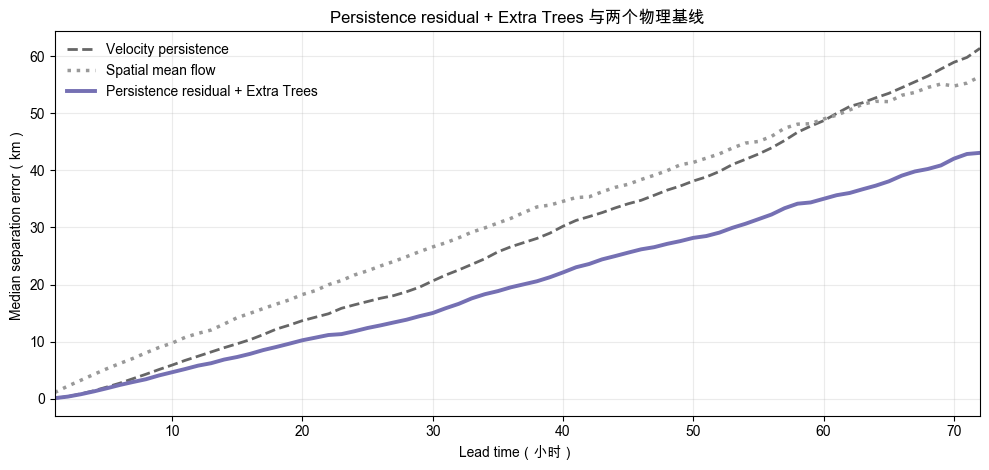

,lead_time_hours,model_median_km,model_rmse_km,persistence_median_km,persistence_rmse_km,mean_flow_median_km,mean_flow_rmse_km,skill_vs_persistence_pct,skill_vs_mean_flow_pct
23,24,11.85,18.90,16.47,24.07,21.69,29.87,21.47,36.72
47,48,27.14,41.89,36.54,55.17,39.96,57.27,24.07,26.85
71,72,43.06,65.04,61.35,90.10,56.42,80.98,27.81,19.68


In [7]:
comparison = compare_with_baselines(
    model_label, lead_metrics, "#7570b3", "physical_residual_extra_trees"
)

## 7. 保存结果

In [8]:
cv_folds.to_csv(OUTPUT_DIR / "physical_residual_extra_trees_cv_folds.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "physical_residual_extra_trees_cv_summary.csv", index=False)
lead_metrics.to_csv(OUTPUT_DIR / "physical_residual_extra_trees_lead_metrics.csv", index=False)
case_metrics.to_csv(OUTPUT_DIR / "physical_residual_extra_trees_test_case_metrics.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "physical_residual_extra_trees_vs_baselines.csv", index=False)
with open(OUTPUT_DIR / "physical_residual_extra_trees_best_parameters.json", "w", encoding="utf-8") as f:
    json.dump({
        "baseline": best_baseline,
        "n_estimators": final_trees,
        **best_params,
    }, f, ensure_ascii=False, indent=2)
print("结果已保存到：", OUTPUT_DIR)

结果已保存到： /Users/roger/Documents/data3001-project/output/rq1/zh
